In [1]:
##Forecasting, predecir datos futuros 

## Exploración inicial con glp1_limpio.csv

65 2021-01-01 00:00:00 2026-05-01 00:00:00
35 2023-02-01 00:00:00 2026-05-01 00:00:00


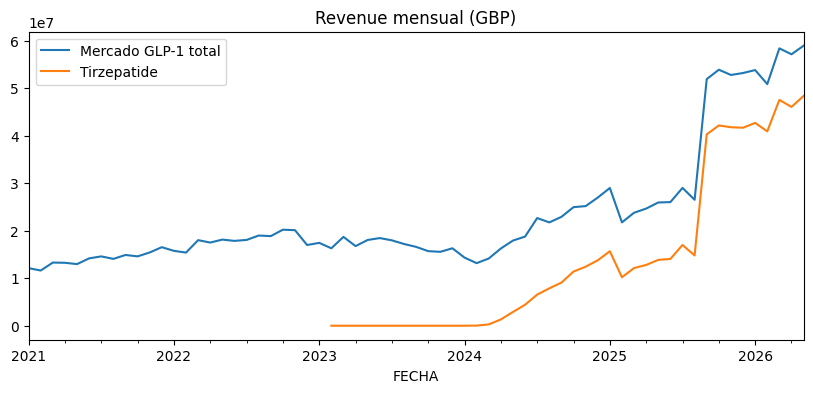

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_final = pd.read_csv("../Práctica 1/glp1_limpio.csv", parse_dates=['FECHA'])

serie_total = df_final.groupby('FECHA')['ACTUAL_COST'].sum()
serie_tirz = df_final[df_final['SUSTANCIA'] == 'Tirzepatide'].groupby('FECHA')['ACTUAL_COST'].sum()

print(len(serie_total), serie_total.index.min(), serie_total.index.max())
print(len(serie_tirz), serie_tirz.index.min(), serie_tirz.index.max())

fig, ax = plt.subplots(figsize=(10, 4))
serie_total.plot(ax=ax, label='Mercado GLP-1 total')
serie_tirz.plot(ax=ax, label='Tirzepatide')
ax.legend()
ax.set_title('Revenue mensual (GBP)')
plt.show()

In [3]:
tirz = df_final[df_final['SUSTANCIA'] == 'Tirzepatide']
chequeo = tirz.groupby('FECHA').agg(
    revenue=('ACTUAL_COST', 'sum'),
    unidades=('TOTAL_QUANTITY', 'sum'),
    recetas=('ITEMS', 'sum')
)
chequeo['precio_por_unidad'] = chequeo['revenue'] / chequeo['unidades']
chequeo.loc['2025-05':'2025-12'].round(1)

,revenue,unidades,recetas,precio_por_unidad
FECHA,,,,
2025-05-01,13869872.0,142655,130096,97.2
2025-06-01,14062471.2,144118,131842,97.6
2025-07-01,17012816.6,173930,159902,97.8
2025-08-01,14801915.1,151266,139730,97.9
2025-09-01,40306878.8,193423,178496,208.4
2025-10-01,42181997.2,201526,186747,209.3
2025-11-01,41808315.2,198304,184184,210.8
2025-12-01,41701436.8,195975,182648,212.8


FECHA
2023-02-01        4
2023-06-01        4
2023-08-01        8
2023-10-01        4
2023-11-01        8
2023-12-01       12
2024-01-01       20
2024-02-01      649
2024-03-01     4730
2024-04-01    16745
2024-05-01    32371
2024-06-01    48370
Name: TOTAL_QUANTITY, dtype: int64


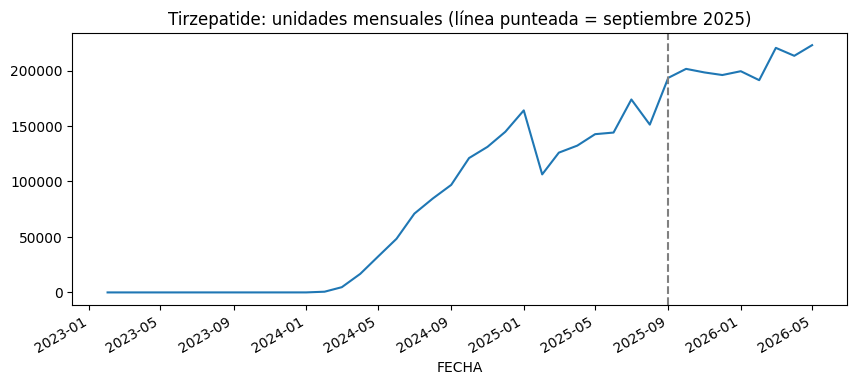

In [4]:
serie_unidades = df_final[df_final['SUSTANCIA'] == 'Tirzepatide'].groupby('FECHA')['TOTAL_QUANTITY'].sum()

print(serie_unidades.loc['2023-01':'2024-06'])

fig, ax = plt.subplots(figsize=(10, 4))
serie_unidades.plot(ax=ax)
ax.axvline(pd.Timestamp('2025-09-01'), color='gray', linestyle='--')
ax.set_title('Tirzepatide: unidades mensuales (línea punteada = septiembre 2025)')
plt.show()

In [5]:
# 1) serie mensual completa desde marzo 2024
u = serie_unidades.asfreq('MS', fill_value=0).loc['2024-03':]
print(len(u), u.index.min(), u.index.max())

# 2) corte por fecha: los últimos 6 meses son la prueba
train = u.iloc[:-6]
test = u.iloc[-6:]
print(train.index.max(), test.index.min(), test.index.max())

# 3) modelo ingenuo: se repite el último valor de entrenamiento
pred_naive = pd.Series(train.iloc[-1], index=test.index)

mae_naive = (test - pred_naive).abs().mean()
mape_naive = ((test - pred_naive).abs() / test).mean() * 100
print(round(mae_naive), round(mape_naive, 1))

27 2024-03-01 00:00:00 2026-05-01 00:00:00
2025-11-01 00:00:00 2025-12-01 00:00:00 2026-05-01 00:00:00
12027 5.6


Pendiente (unidades por mes): 8688 | R² en entrenamiento: 0.866
                  MAE (unidades)  MAPE (%)
Ingenuo                  12026.8       5.6
Regresión lineal         28440.9      13.8
Holt amortiguado          7757.1       3.9


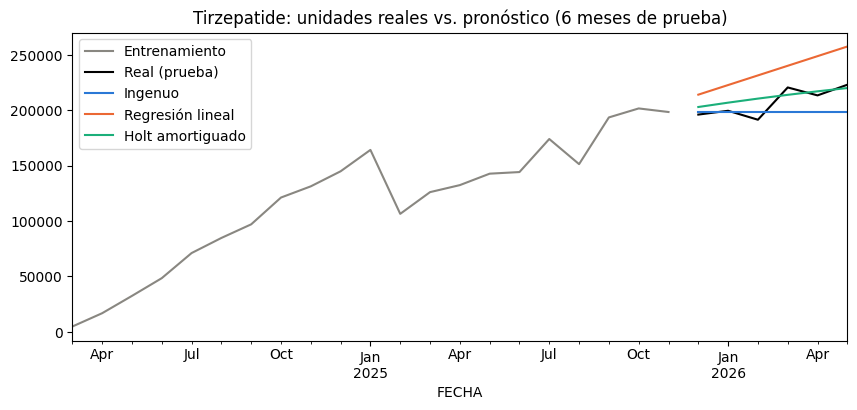

In [6]:
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Modelo 2: regresión lineal contra el tiempo ---
t_train = np.arange(len(train))
t_test = np.arange(len(train), len(train) + len(test))

res = stats.linregress(t_train, train.values)
pred_lin = pd.Series(res.intercept + res.slope * t_test, index=test.index)

mae_lin = (test - pred_lin).abs().mean()
mape_lin = ((test - pred_lin).abs() / test).mean() * 100
print("Pendiente (unidades por mes):", round(res.slope), "| R² en entrenamiento:", round(res.rvalue**2, 3))

# --- Modelo 3: Holt con tendencia amortiguada ---
holt = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal=None).fit()
pred_holt = holt.forecast(len(test))
pred_holt.index = test.index

mae_holt = (test - pred_holt).abs().mean()
mape_holt = ((test - pred_holt).abs() / test).mean() * 100

# --- Comparación ---
resultados = pd.DataFrame(
    {'MAE (unidades)': [mae_naive, mae_lin, mae_holt],
     'MAPE (%)': [mape_naive, mape_lin, mape_holt]},
    index=['Ingenuo', 'Regresión lineal', 'Holt amortiguado']
).round(1)
print(resultados)

fig, ax = plt.subplots(figsize=(10, 4))
train.plot(ax=ax, label='Entrenamiento', color='#898781')
test.plot(ax=ax, label='Real (prueba)', color='black')
pred_naive.plot(ax=ax, label='Ingenuo', color='#2a78d6')
pred_lin.plot(ax=ax, label='Regresión lineal', color='#eb6834')
pred_holt.plot(ax=ax, label='Holt amortiguado', color='#1baf7a')
ax.legend()
ax.set_title('Tirzepatide: unidades reales vs. pronóstico (6 meses de prueba)')
plt.show()

2026-06-01    222453.0
2026-07-01    224963.0
2026-08-01    227300.0
2026-09-01    229475.0
2026-10-01    231499.0
2026-11-01    233383.0
Freq: MS, dtype: float64


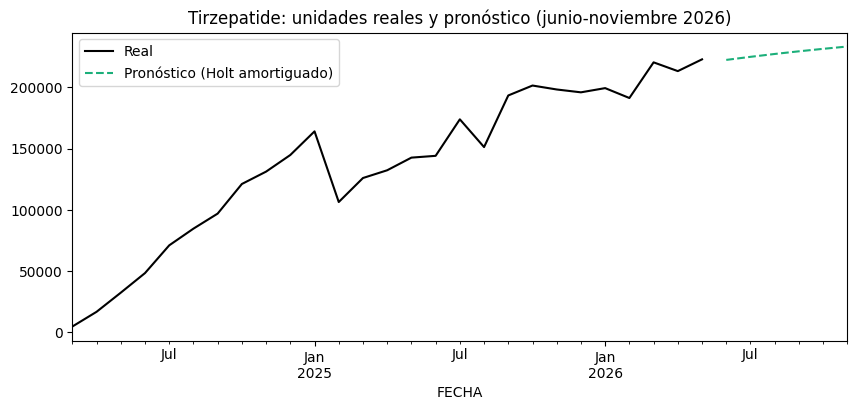

In [7]:
holt_final = ExponentialSmoothing(u, trend='add', damped_trend=True, seasonal=None).fit()
pron = holt_final.forecast(6)   # junio a noviembre de 2026
print(pron.round())

fig, ax = plt.subplots(figsize=(10, 4))
u.plot(ax=ax, label='Real', color='black')
pron.plot(ax=ax, label='Pronóstico (Holt amortiguado)', color='#1baf7a', linestyle='--')
ax.legend()
ax.set_title('Tirzepatide: unidades reales y pronóstico (junio-noviembre 2026)')
plt.show()

In [8]:
tirz = df_final[df_final['SUSTANCIA'] == 'Tirzepatide']
agg = tirz.groupby('FECHA')[['ACTUAL_COST', 'TOTAL_QUANTITY']].sum()
precio_mes = agg['ACTUAL_COST'] / agg['TOTAL_QUANTITY']

print(precio_mes.loc['2025-09':].round(1))

precio_supuesto = precio_mes.loc['2026-03':'2026-05'].mean()
print("Precio supuesto (promedio mar-may 2026):", round(precio_supuesto, 1))

escenarios = pd.DataFrame({
    'Unidades': pron.round(),
    'Libras, precio -10% (M)': pron * precio_supuesto * 0.9 / 1e6,
    'Libras, precio base (M)': pron * precio_supuesto / 1e6,
    'Libras, precio +10% (M)': pron * precio_supuesto * 1.1 / 1e6,
}).round(1)
print(escenarios)

FECHA
2025-09-01    208.4
2025-10-01    209.3
2025-11-01    210.8
2025-12-01    212.8
2026-01-01    214.2
2026-02-01    214.0
2026-03-01    215.8
2026-04-01    216.1
2026-05-01    217.1
dtype: float64
Precio supuesto (promedio mar-may 2026): 216.3
            Unidades  Libras, precio -10% (M)  Libras, precio base (M)  \
2026-06-01  222453.0                     43.3                     48.1   
2026-07-01  224963.0                     43.8                     48.7   
2026-08-01  227300.0                     44.3                     49.2   
2026-09-01  229475.0                     44.7                     49.6   
2026-10-01  231499.0                     45.1                     50.1   
2026-11-01  233383.0                     45.4                     50.5   

            Libras, precio +10% (M)  
2026-06-01                     52.9  
2026-07-01                     53.5  
2026-08-01                     54.1  
2026-09-01                     54.6  
2026-10-01                     55.1  
2026-

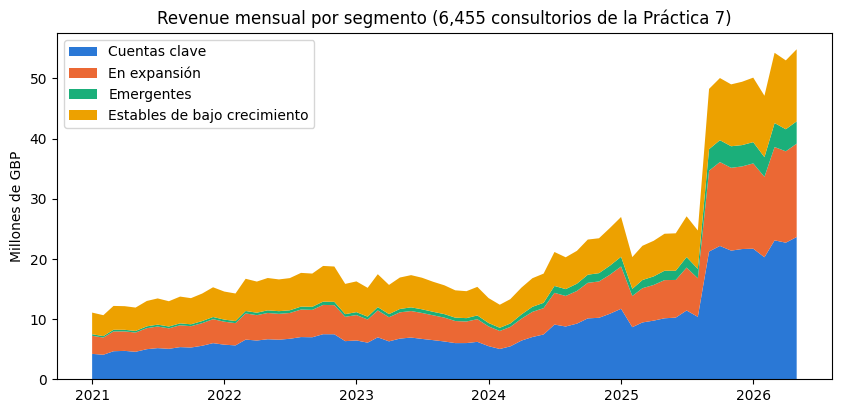

In [9]:
segmentos = pd.read_csv("../Práctica 7/segmentos_p7.csv")
df_seg = df_final.merge(segmentos, on='PRACTICE_CODE', how='inner')

orden = ['Cuentas clave', 'En expansión', 'Emergentes', 'Estables de bajo crecimiento']
rev_seg = (df_seg.pivot_table(index='FECHA', columns='segmento', values='ACTUAL_COST', aggfunc='sum') / 1e6)[orden]

colores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # mismos colores que en la Práctica 7

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(rev_seg.index, rev_seg.T.values, labels=orden, colors=colores)
ax.legend(loc='upper left')
ax.set_ylabel('Millones de GBP')
ax.set_title('Revenue mensual por segmento (6,455 consultorios de la Práctica 7)')
plt.show()

In [10]:
#### Versión final: serie exacta desde la API

In [11]:
import requests

BASE_URL = "https://opendata.nhsbsa.net/api/3/action/datastore_search_sql?"

def extraer_records(j):  
    nivel1 = j.get('result', {})
    if 'records' in nivel1:
        return nivel1['records']
    else:
        nivel2 = nivel1.get('result', {})
        return nivel2.get('records', [])

In [12]:
import time

meses_tirz = [f.strftime('%Y%m') for f in pd.date_range('2024-01-01', '2026-08-01', freq='MS')]
filas = []
for mes in meses_tirz:
    resource_id = f"EPD_SNOMED_{mes}"
    columna = "BNF_CHEMICAL_SUBSTANCE" if mes >= "202503" else "CHEMICAL_SUBSTANCE_BNF_DESCR"
    sql = f"""SELECT COUNT(*) AS n_filas,
                     SUM(SAFE_CAST(TOTAL_QUANTITY AS FLOAT64)) AS unidades,
                     SUM(SAFE_CAST(ACTUAL_COST AS FLOAT64)) AS revenue
              FROM `{resource_id}` WHERE {columna} = 'Tirzepatide'"""
    r = requests.get(BASE_URL, params={'resource_id': resource_id, 'sql': sql}, timeout=60)
    if r.status_code != 200:
        raise RuntimeError(f"{mes}: {r.status_code} {r.text[:200]}")
    rec = extraer_records(r.json())
    if not rec:
        raise RuntimeError(f"{mes}: la API no devolvió registros")
    filas.append({'mes': mes, **rec[0]})
    time.sleep(0.3)

api_tirz = pd.DataFrame(filas)
for c in ['n_filas', 'unidades', 'revenue']:
    api_tirz[c] = pd.to_numeric(api_tirz[c])
api_tirz['FECHA'] = pd.to_datetime(api_tirz['mes'], format='%Y%m')
api_tirz = api_tirz.set_index('FECHA')

print(len(api_tirz), "meses")                  # debe salir 32
print(api_tirz[['n_filas', 'unidades', 'revenue']].tail(8))

32 meses
            n_filas  unidades       revenue
FECHA                                      
2026-01-01    49182  314693.0  6.720435e+07
2026-02-01    48666  294257.0  6.308943e+07
2026-03-01    50826  331797.0  7.147743e+07
2026-04-01    51222  332260.0  7.191011e+07
2026-05-01    51966  336433.0  7.301576e+07
2026-06-01    53478  364371.0  7.918326e+07
2026-07-01    55091  392320.0  8.557698e+07
2026-08-01    54368  364613.0  7.983491e+07


In [13]:
serie_unidades = api_tirz['unidades']
precio_mes = api_tirz['revenue'] / api_tirz['unidades']

u = serie_unidades.asfreq('MS').loc['2024-03':'2026-05']     
real = serie_unidades.loc['2026-06':'2026-08']               
print("meses sin dato en u:", u.isna().sum())                 
print(u.tail(3))
print(real)

meses sin dato en u: 0
FECHA
2026-03-01    331797.0
2026-04-01    332260.0
2026-05-01    336433.0
Freq: MS, Name: unidades, dtype: float64
FECHA
2026-06-01    364371.0
2026-07-01    392320.0
2026-08-01    364613.0
Name: unidades, dtype: float64


In [14]:
for col in ["CHEMICAL_SUBSTANCE_BNF_DESCR", "BNF_CHEMICAL_SUBSTANCE"]:
    sql = f"SELECT COUNT(*) AS n FROM `EPD_SNOMED_202503` where {col} = 'Tirzepatide'"
    r = requests.get(BASE_URL, params={'resource_id': 'EPD_SNOMED_202503', 'sql': sql}, timeout=60)
    print(col, '| status:', r.status_code)
    print(r.text[:400])
    print('---')

sql = "SELECT * FROM `EPD_SNOMED_202503` LIMIT 1"
r = requests.get(BASE_URL, params={'resource_id': 'EPD_SNOMED_202503', 'sql': sql}, timeout=60)
print(r.status_code, r.text[:800])

CHEMICAL_SUBSTANCE_BNF_DESCR | status: 400
{"help": "https://opendata.nhsbsa.net/api/3/action/help_show?name=datastore_search_sql", "error": {"__type": "Search Query Error", "message": "Search Query is invalid: 'Unrecognized name: CHEMICAL_SUBSTANCE_BNF_DESCR at [1:68]; reason: invalidQuery, location: query, message: Unrecognized name: CHEMICAL_SUBSTANCE_BNF_DESCR at [1:68]\\n\\nLocation: europe-west1\\nJob ID: 89af2225-9b8a-4582-a7a2-f41e
---
BNF_CHEMICAL_SUBSTANCE | status: 200
{"help": "https://opendata.nhsbsa.net/api/3/action/help_show?name=datastore_search_sql", "success": true, "result": {"help": "https://demo.ckan.org/api/3/action/help_show?name=datastore_search_sql", "success": "true", "result": {"records": [{"n": 35204}], "fields": []}}}
---
200 {"help": "https://opendata.nhsbsa.net/api/3/action/help_show?name=datastore_search_sql", "success": true, "result": {"help": "https://demo.ckan.org/api/3/action/help_show?name=datastore_search_sql", "success": "true", "result": {"recor

In [15]:
sql = "SELECT COUNT(*) AS n_filas, SUM(TOTAL_QUANTITY) AS unidades, SUM(ACTUAL_COST) AS revenue FROM `EPD_SNOMED_202503` where BNF_CHEMICAL_SUBSTANCE = 'Tirzepatide'"
r = requests.get(BASE_URL, params={'resource_id': 'EPD_SNOMED_202503', 'sql': sql}, timeout=60)
print(r.status_code, r.text[:500])

sql = "SELECT * FROM `EPD_SNOMED_202503` LIMIT 1"
r = requests.get(BASE_URL, params={'resource_id': 'EPD_SNOMED_202503', 'sql': sql}, timeout=60)
print(list(extraer_records(r.json())[0].keys()))

400 {"help": "https://opendata.nhsbsa.net/api/3/action/help_show?name=datastore_search_sql", "error": {"__type": "Search Query Error", "message": "Search Query is invalid: 'No matching signature for aggregate function SUM\\n  Argument types: STRING\\n  Signature: SUM(INT64)\\n    Argument 1: Unable to coerce type STRING to expected type INT64\\n  Signature: SUM(FLOAT64)\\n    Argument 1: Unable to coerce type STRING to expected type FLOAT64\\n  Signature: SUM(NUMERIC)\\n    Argument 1: Unable to coe
['YEAR_MONTH', 'REGIONAL_OFFICE_NAME', 'REGIONAL_OFFICE_CODE', 'ICB_NAME', 'ICB_CODE', 'PCO_NAME', 'PCO_CODE', 'PRACTICE_NAME', 'PRACTICE_CODE', 'ADDRESS_1', 'ADDRESS_2', 'ADDRESS_3', 'ADDRESS_4', 'POSTCODE', 'BNF_CHEMICAL_SUBSTANCE_CODE', 'BNF_CHEMICAL_SUBSTANCE', 'BNF_PRESENTATION_CODE', 'BNF_PRESENTATION_NAME', 'BNF_CHAPTER_PLUS_CODE', 'QUANTITY', 'ITEMS', 'TOTAL_QUANTITY', 'ADQ_USAGE', 'NIC', 'ACTUAL_COST', 'UNIDENTIFIED', 'SNOMED_CODE']


In [16]:
sql = """SELECT COUNT(*) AS n_filas,
                SUM(SAFE_CAST(TOTAL_QUANTITY AS FLOAT64)) AS unidades,
                SUM(SAFE_CAST(ACTUAL_COST AS FLOAT64)) AS revenue
         FROM `EPD_SNOMED_202503` where BNF_CHEMICAL_SUBSTANCE = 'Tirzepatide'"""
r = requests.get(BASE_URL, params={'resource_id': 'EPD_SNOMED_202503', 'sql': sql}, timeout=60)
print(r.status_code)
rec = extraer_records(r.json())
print(rec)

api_tirz.loc[pd.Timestamp('2025-03-01'), ['n_filas', 'unidades', 'revenue']] = [float(rec[0]['n_filas']), float(rec[0]['unidades']), float(rec[0]['revenue'])]
api_tirz = api_tirz.sort_index()
print(api_tirz.loc['2025-01':'2025-06', ['unidades', 'revenue']])

200
[{'n_filas': 35204, 'unidades': 186923.0, 'revenue': 18013232.080720033}]
            unidades       revenue
FECHA                             
2025-01-01  164162.0  1.569463e+07
2025-02-01  161629.0  1.550888e+07
2025-03-01  186923.0  1.801323e+07
2025-04-01  201688.0  1.951014e+07
2025-05-01  225870.0  2.194870e+07
2025-06-01  234962.0  2.290706e+07


In [17]:
serie_unidades = api_tirz['unidades']
precio_mes = api_tirz['revenue'] / api_tirz['unidades']

u = serie_unidades.asfreq('MS').loc['2024-03':'2026-05']
real = serie_unidades.loc['2026-06':'2026-08']
print("meses sin dato en u:", u.isna().sum())      
print("meses en u:", len(u))
print(precio_mes.loc['2025-06':'2025-11'].round(1))

meses sin dato en u: 0
meses en u: 27
FECHA
2025-06-01     97.5
2025-07-01     97.8
2025-08-01     97.9
2025-09-01    208.5
2025-10-01    209.3
2025-11-01    210.9
dtype: float64


In [18]:
import numpy as np
import pandas as pd
from scipy.stats import linregress
from statsmodels.tsa.holtwinters import ExponentialSmoothing

print(u.index[0], u.index[-1], len(u))   

train2, test2 = u.iloc[:-6], u.iloc[-6:]

def metricas(real_s, pred_s):
    mae = (real_s - pred_s).abs().mean()
    mape = ((real_s - pred_s).abs() / real_s).mean() * 100
    return round(mae), round(mape, 1)

# Naive: repetir el último valor de train
pred_naive2 = pd.Series(train2.iloc[-1], index=test2.index)

# Lineal: recta sobre el tiempo
t_train = np.arange(len(train2))
t_test = np.arange(len(train2), len(train2) + len(test2))
reg = linregress(t_train, train2.values)
pred_lin2 = pd.Series(reg.intercept + reg.slope * t_test, index=test2.index)

# Holt con tendencia amortiguada
holt_tr = ExponentialSmoothing(train2, trend='add', damped_trend=True, seasonal=None).fit()
pred_holt2 = holt_tr.forecast(6)

res = []
for nombre, pred in [('Naive', pred_naive2), ('Lineal', pred_lin2), ('Holt amortiguado', pred_holt2)]:
    mae, mape = metricas(test2, pred)
    res.append({'Modelo': nombre, 'MAE': mae, 'MAPE %': mape})
print(pd.DataFrame(res))

2024-03-01 00:00:00 2026-05-01 00:00:00 27
             Modelo    MAE  MAPE %
0             Naive  36206    11.1
1            Lineal  40148    12.5
2  Holt amortiguado  30093     9.4


In [19]:
# Los tres modelos reentrenados con toda u (hasta mayo 2026), pronosticando 3 meses
holt_f2 = ExponentialSmoothing(u, trend='add', damped_trend=True, seasonal=None).fit()
pron_holt = holt_f2.forecast(3)

t_all = np.arange(len(u))
reg_all = linregress(t_all, u.values)
pron_lin = pd.Series(reg_all.intercept + reg_all.slope * np.arange(len(u), len(u) + 3), index=real.index)
pron_naive = pd.Series(u.iloc[-1], index=real.index)

val = pd.DataFrame({
    'Real': real,
    'Naive': pron_naive.round(),
    'Lineal': pron_lin.round(),
    'Holt': pron_holt.values.round(),
})
print(val)

res_val = []
for nombre, pred in [('Naive', pron_naive), ('Lineal', pron_lin), ('Holt amortiguado', pd.Series(pron_holt.values, index=real.index))]:
    mae, mape = metricas(real, pred)
    res_val.append({'Modelo': nombre, 'MAE': mae, 'MAPE %': mape})
print(pd.DataFrame(res_val))

                Real     Naive    Lineal      Holt
FECHA                                             
2026-06-01  364371.0  336433.0  382128.0  359531.0
2026-07-01  392320.0  336433.0  395560.0  368659.0
2026-08-01  364613.0  336433.0  408992.0  377563.0
             Modelo    MAE  MAPE %
0             Naive  37335     9.9
1            Lineal  21792     6.0
2  Holt amortiguado  13817     3.6


In [20]:
u_full = serie_unidades.asfreq('MS').loc['2024-03':'2026-08']
print("huecos:", u_full.isna().sum(), "| meses:", len(u_full))   

holt_full = ExponentialSmoothing(u_full, trend='add', damped_trend=True, seasonal=None).fit()
pron_unidades = holt_full.forecast(6)          # sep 2026 – feb 2027
print("phi (amortiguamiento):", round(holt_full.params['damping_trend'], 3))

precio_ref = precio_mes.loc['2026-06':'2026-08'].mean()
print("precio de referencia jun-ago 2026: £", round(precio_ref, 1))

esc = pd.DataFrame({
    'unidades': pron_unidades.round(),
    'revenue_base_£M': pron_unidades * precio_ref / 1e6,
    'revenue_-10%_£M': pron_unidades * precio_ref * 0.9 / 1e6,
    'revenue_+10%_£M': pron_unidades * precio_ref * 1.1 / 1e6,
}).round(2)
print(esc)

huecos: 0 | meses: 30
phi (amortiguamiento): 0.977
precio de referencia jun-ago 2026: £ 218.1
            unidades  revenue_base_£M  revenue_-10%_£M  revenue_+10%_£M
2026-09-01  390300.0            85.14            76.62            93.65
2026-10-01  399167.0            87.07            78.36            95.78
2026-11-01  407831.0            88.96            80.07            97.86
2026-12-01  416298.0            90.81            81.73            99.89
2027-01-01  424573.0            92.61            83.35           101.88
2027-02-01  432659.0            94.38            84.94           103.82


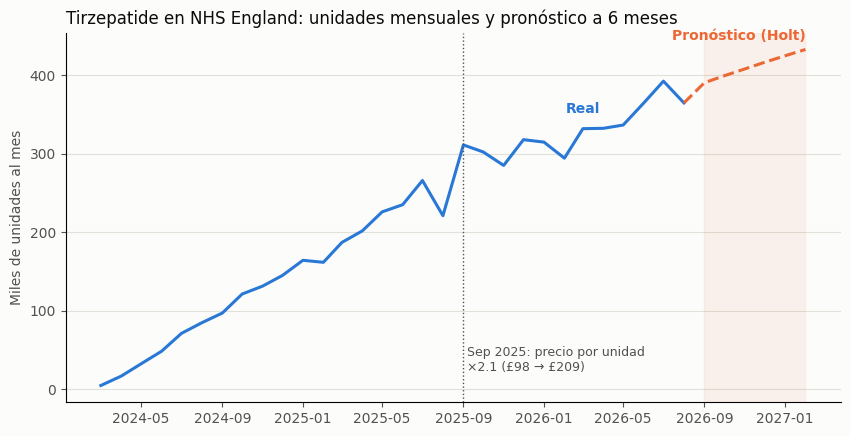

In [21]:
import matplotlib.pyplot as plt

AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
TINTA, GRIS, FONDO, REJILLA = '#0b0b0b', '#52514e', '#fcfcfb', '#e1e0d9'

fig, ax = plt.subplots(figsize=(10, 4.8))
fig.patch.set_facecolor(FONDO); ax.set_facecolor(FONDO)

ax.plot(u_full.index, u_full / 1e3, color=AZUL, lw=2.2)
union = pd.concat([u_full.iloc[[-1]], pron_unidades])
ax.plot(union.index, union / 1e3, color=NARANJA, lw=2.2, ls='--')
ax.axvspan(pron_unidades.index[0], pron_unidades.index[-1], color=NARANJA, alpha=0.08)

# marca del salto de precio
f_precio = pd.Timestamp('2025-09-01')
ax.axvline(f_precio, color=GRIS, lw=1, ls=':')
ax.text(f_precio, 20, ' Sep 2025: precio por unidad\n ×2.1 (£98 → £209)', color=GRIS, fontsize=9, va='bottom')

# etiquetas directas
ax.text(pd.Timestamp('2026-03-01'), 352, 'Real', color=AZUL, fontsize=10, fontweight='bold', ha='center')
ax.text(pron_unidades.index[-1], pron_unidades.iloc[-1] / 1e3 + 12, 'Pronóstico (Holt)', color=NARANJA, fontsize=10, fontweight='bold', ha='right')

ax.set_ylabel('Miles de unidades al mes', color=GRIS)
ax.set_title('Tirzepatide en NHS England: unidades mensuales y pronóstico a 6 meses', color=TINTA, loc='left', fontsize=12)
ax.grid(axis='y', color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=GRIS)
fig.savefig('p8_pronostico.png', dpi=200, bbox_inches='tight', facecolor=FONDO)
plt.show()

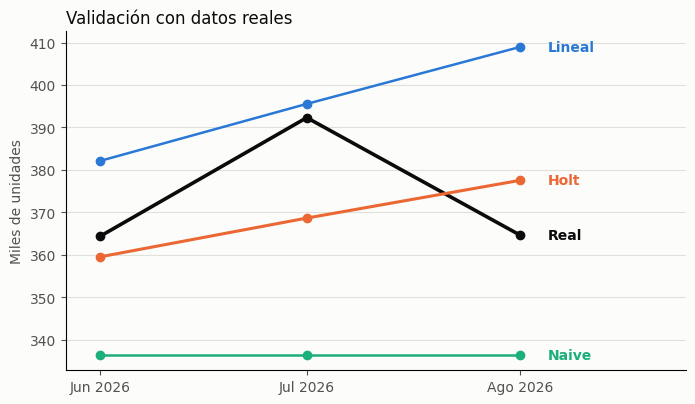

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.4))
fig.patch.set_facecolor(FONDO); ax.set_facecolor(FONDO)

ax.plot(val.index, val['Real'] / 1e3, color=TINTA, lw=2.6, marker='o')
ax.plot(val.index, val['Naive'] / 1e3, color=AQUA, lw=1.8, marker='o')
ax.plot(val.index, val['Lineal'] / 1e3, color=AZUL, lw=1.8, marker='o')
ax.plot(val.index, val['Holt'] / 1e3, color=NARANJA, lw=2.2, marker='o')

x_fin = val.index[-1] + pd.Timedelta(days=4)
for col, color in [('Real', TINTA), ('Naive', AQUA), ('Lineal', AZUL), ('Holt', NARANJA)]:
    ax.text(x_fin, val[col].iloc[-1] / 1e3, col, color=color, fontsize=10, fontweight='bold', va='center')

ax.set_xlim(val.index[0] - pd.Timedelta(days=5), val.index[-1] + pd.Timedelta(days=24))
ax.set_xticks(val.index); ax.set_xticklabels(['Jun 2026', 'Jul 2026', 'Ago 2026'])
ax.set_ylabel('Miles de unidades', color=GRIS)
ax.set_title('Validación con datos reales', color=TINTA, loc='left', fontsize=12)
ax.grid(axis='y', color=REJILLA, lw=0.8); ax.set_axisbelow(True)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.tick_params(colors=GRIS)
fig.savefig('p8_validacion.png', dpi=200, bbox_inches='tight', facecolor=FONDO)
plt.show()